# 05 · Classification Models — reorder / stockout risk

Unit 2: discriminant functions, probabilistic generative vs discriminative models, kernels, the kernel trick and SVMs.

> **Data provenance.** Sales, dates, prices, SKUs and countries are **real**
> (UCI Online Retail II, CC BY 4.0, 1,067,371 invoice lines).
> Stock levels, suppliers, lead times, MOQ, pack sizes and every cost are
> **SIMULATED** — the source dataset contains none of them. See `sim/` and
> `docs/pbl1_scope.md`.


In [1]:
import sys, os
from pathlib import Path
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

from xaierp.utils.config import load_config, resolve
CFG = load_config()
REPORTS = resolve(CFG["paths"]["reports"])
FIGS = resolve(CFG["paths"]["figures"])
print("project root:", ROOT)


project root: E:\downloads\ML Project


## Results

In [2]:
clf = pd.read_csv(REPORTS / 'classification_model_comparison.csv')
clf[['model', 'unit', 'n_train_rows_used', 'test_accuracy',
     'test_precision', 'test_recall', 'test_f1', 'test_roc_auc',
     'train_time_s']].round(4)

,model,unit,n_train_rows_used,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,train_time_s
0,LightGBM Classifier,Advanced (beyond syllabus),66859,0.8525,0.7438,0.8155,0.7780,0.9205,13.540
1,SVM (linear kernel),Unit 2,15000,0.8261,0.6912,0.8157,0.7483,0.8987,44.456
2,Logistic Regression,Unit 2,66859,0.8238,0.6840,0.8257,0.7482,0.8977,1.496
3,SVM (RBF kernel),Unit 2,15000,0.7859,0.6164,0.8594,0.7179,0.8906,26.717
4,Linear Discriminant Analysis,Unit 2,66859,0.7803,0.7809,0.4265,0.5517,0.8500,0.625
5,Gaussian Naive Bayes,Unit 2 (+ Unit 1 Bayes rule),66859,0.4758,0.3739,0.9694,0.5397,0.7690,0.243


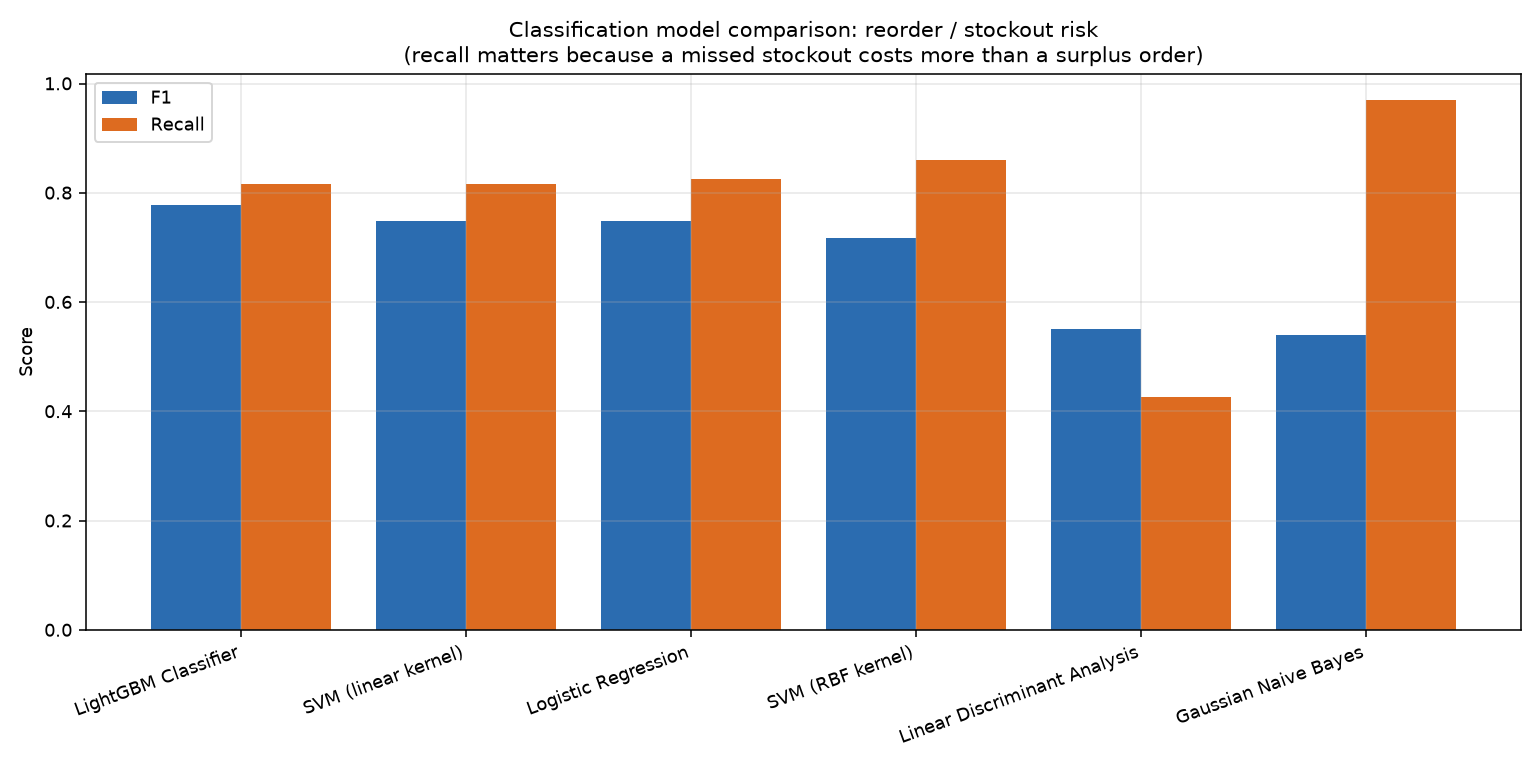

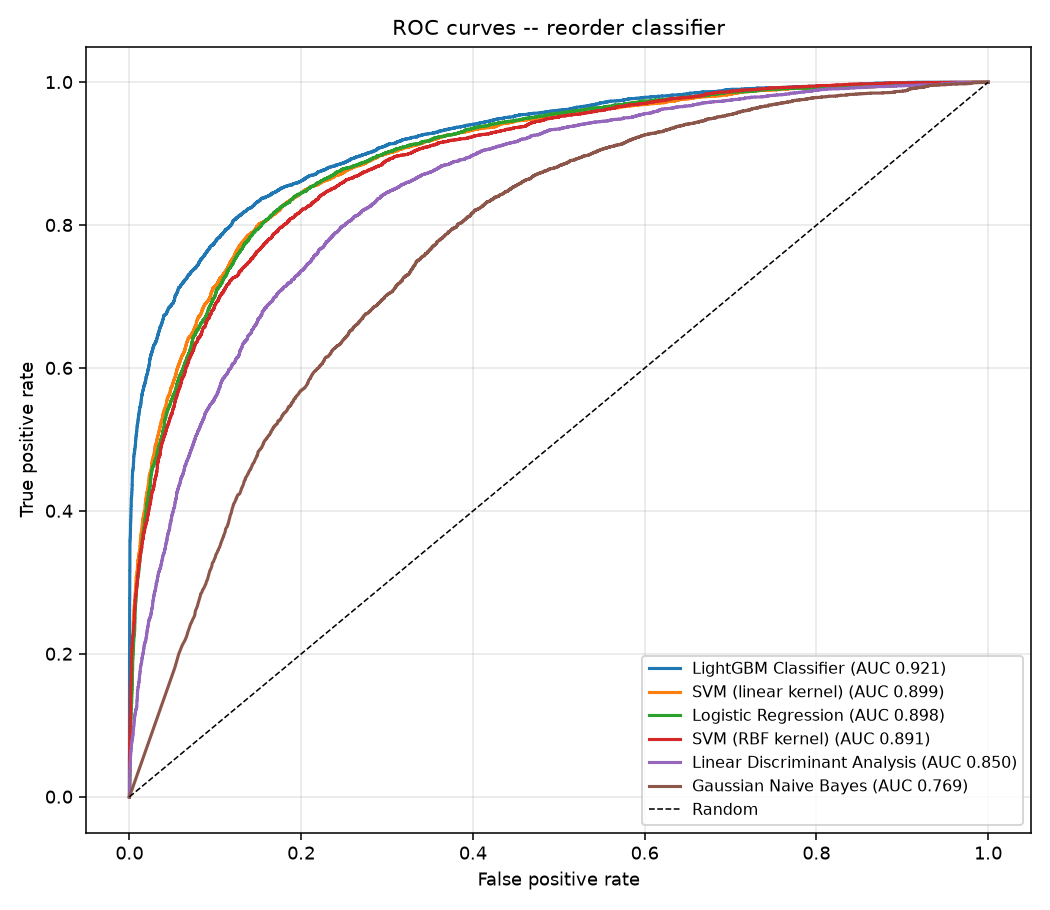

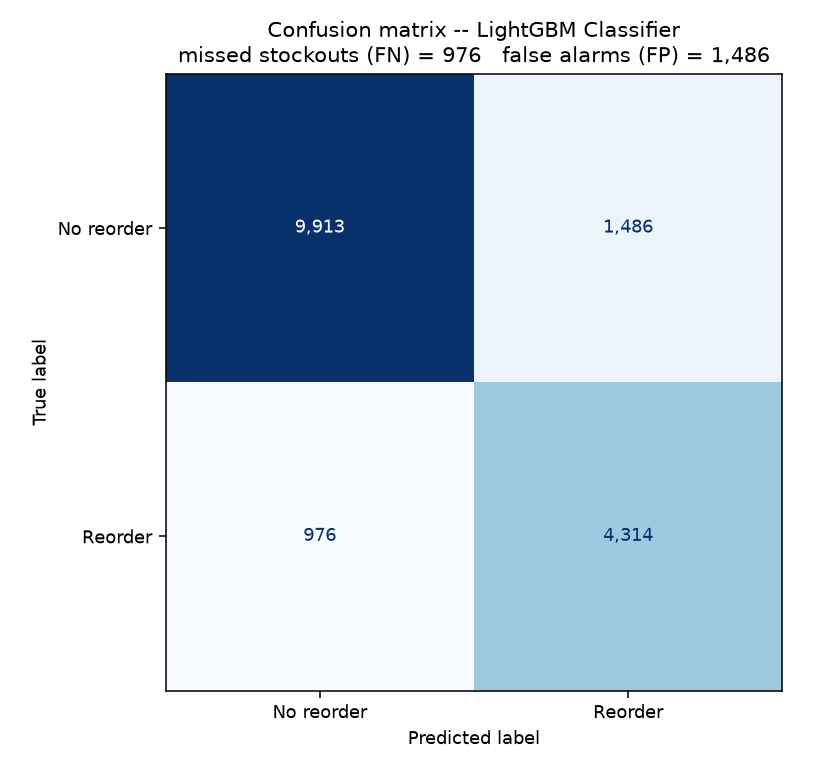

In [3]:
from IPython.display import Image, display
display(Image(filename=str(FIGS / 'model_classification_f1.png')))
display(Image(filename=str(FIGS / 'model_roc_curves.png')))
display(Image(filename=str(FIGS / 'model_confusion_matrix.png')))

## Syllabus mapping

In [4]:
clf[['model', 'unit', 'concept']]

,model,unit,concept
0,LightGBM Classifier,Advanced (beyond syllabus),Non-linear ensemble; TreeSHAP explanations for...
1,SVM (linear kernel),Unit 2,Support vector machine; maximum-margin linear ...
2,Logistic Regression,Unit 2,Probabilistic discriminative model; models p(y...
3,SVM (RBF kernel),Unit 2,Kernel function / kernel trick; non-linear bou...
4,Linear Discriminant Analysis,Unit 2,Discriminant function; linear decision boundar...
5,Gaussian Naive Bayes,Unit 2 (+ Unit 1 Bayes rule),Probabilistic generative model; models p(x|y)p...


## Generative vs discriminative — the clearest contrast in the table

In [5]:
pair = clf[clf['key'].isin(['gaussian_nb', 'logistic_regression'])]
display(pair[['model', 'test_precision', 'test_recall', 'test_f1',
              'test_roc_auc']].round(4))
nb_ = clf.loc[clf['key'] == 'gaussian_nb'].iloc[0]
lr = clf.loc[clf['key'] == 'logistic_regression'].iloc[0]
print(f"Naive Bayes recall {nb_['test_recall']:.3f} but F1 only {nb_['test_f1']:.3f}")
print(f"Logistic   recall {lr['test_recall']:.3f} and F1 {lr['test_f1']:.3f}")

,model,test_precision,test_recall,test_f1,test_roc_auc
2,Logistic Regression,0.6840,0.8257,0.7482,0.8977
5,Gaussian Naive Bayes,0.3739,0.9694,0.5397,0.7690


Naive Bayes recall 0.969 but F1 only 0.540
Logistic   recall 0.826 and F1 0.748


Gaussian Naive Bayes models `p(x|y)p(y)` and inverts it with **Bayes rule** (Unit 1). Its independence assumption is badly violated here — `rolling_mean_7` and `rolling_mean_28` are strongly correlated — so it becomes over-confident and flags almost everything as needing a reorder: very high recall, poor precision. Logistic regression models `p(y|x)` directly, makes no claim about how the features are distributed, and is far better calibrated.

## The kernel trick: linear vs RBF SVM

In [6]:
k = clf[clf['key'].isin(['svm_linear', 'svm_rbf'])]
k[['model', 'n_train_rows_used', 'test_precision', 'test_recall',
   'test_f1', 'test_roc_auc', 'train_time_s']].round(4)

,model,n_train_rows_used,test_precision,test_recall,test_f1,test_roc_auc,train_time_s
1,SVM (linear kernel),15000,0.6912,0.8157,0.7483,0.8987,44.456
3,SVM (RBF kernel),15000,0.6164,0.8594,0.7179,0.8906,26.717


Both SVMs use the same C, the same features and the same training subsample, so the only difference is the kernel.

* **Linear kernel** `K(x,z) = xᵀz` — a hyperplane in the original space.
* **RBF kernel** `K(x,z) = exp(−γ‖x−z‖²)` — a hyperplane in an infinite-dimensional space.

The **kernel trick** is that the algorithm only ever needs inner products, so that infinite-dimensional map is never computed — only `K`. Note the result below: the extra flexibility did **not** help here, which is itself worth saying out loud.

In [7]:
lin = clf.loc[clf['key'] == 'svm_linear', 'test_f1'].iloc[0]
rbf = clf.loc[clf['key'] == 'svm_rbf', 'test_f1'].iloc[0]
print(f'Linear SVM F1 {lin:.4f} vs RBF SVM F1 {rbf:.4f} -> '
      f'{"RBF" if rbf > lin else "LINEAR"} wins')
print('The decision boundary is close to linear in these features.')

Linear SVM F1 0.7483 vs RBF SVM F1 0.7179 -> LINEAR wins
The decision boundary is close to linear in these features.


## Why F1 and recall, not accuracy

In [8]:
feats_rate = pd.read_parquet(
    resolve(CFG['paths']['processed']) / 'feature_table.parquet')
rate = feats_rate['reorder_flag'].mean()
print(f'positive (reorder needed) rate: {rate:.2%}')
print(f'a model that always says NO scores {1-rate:.2%} accuracy '
      'while catching zero stockouts')
print(f"best model accuracy: {clf['test_accuracy'].max():.2%}")

positive (reorder needed) rate: 30.77%
a model that always says NO scores 69.23% accuracy while catching zero stockouts
best model accuracy: 85.25%


A missed stockout (false negative) loses a sale and customer goodwill; a false alarm just ties up working capital. Recall is therefore weighted more heavily than precision, and accuracy alone is reported but never relied on.